

*   Line plots for time-series data.
*   Bar charts for category-wise comparisons.
*   Histograms for distribution analysis.
*   Scatter plots for identifying relationships between variables.



**Exercise 1: Understanding Data Visualization**

**Task**: Explain why data visualization is important in data analysis. A: because it helps understand better the data - distribution, relationships between different variables/dimesntions of the data

**Task**: Describe the purpose of a line graph in data visualization. A: it's useful to visualize time-dependent data points

**Exercise 2: Creating a Line Plot for Temperature Variation**
**Objective:** Create a simple line plot using Matplotlib that represents temperature variations over a week.

**Tasks:**
Use a list of temperature values for each day of the week (e.g., [72, 74, 76, 80, 82, 78, 75]).
Label the x-axis as “Day” and the y-axis as “Temperature (°F)”.
Add a title to the plot.
Display the plot.

In [1]:
import matplotlib.pyplot as plt

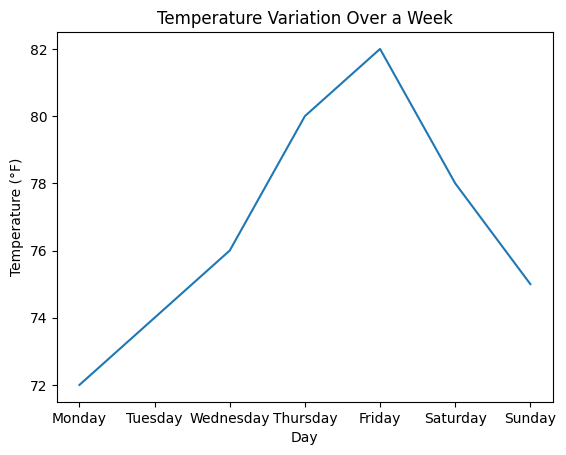

In [2]:
days= ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
temp = [72, 74, 76, 80, 82, 78, 75]

plt.plot(days, temp)
plt.xlabel('Day')
plt.ylabel('Temperature (°F)')
plt.title('Temperature Variation Over a Week')
plt.show()

**Exercise 3: Visualizing Monthly Sales with a Bar Chart**

**Objective**: Generate a bar chart using Matplotlib to visualize monthly sales data for a retail store.

**Tasks:**
Create a list of sales values for each month (e.g., [5000, 5500, 6200, 7000, 7500]).
Label the x-axis as “Month” and the y-axis as “Sales Amount ($)”.
Add a title to the bar chart.
Display the plot.

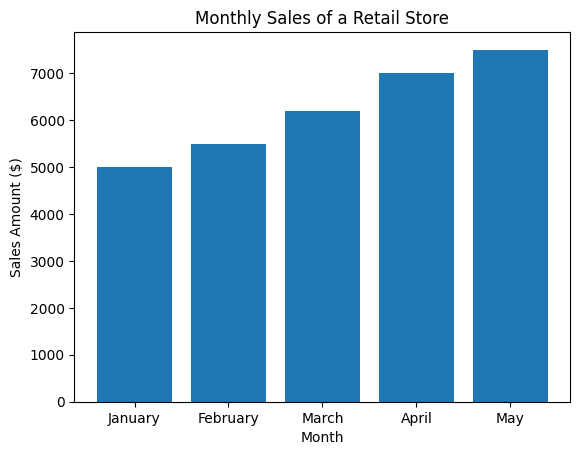

In [3]:
sales = [5000, 5500, 6200, 7000, 7500]
months = ['January', 'February', 'March', 'April', 'May']

plt.bar(months, sales)
plt.xlabel('Month')
plt.ylabel('Sales Amount ($)')
plt.title('Monthly Sales of a Retail Store')
plt.show()

**Exercise 4: Visualizing the Distribution of CGPA**
**Objective**: Create a histogram to visualize the distribution of students’ CGPA.

**Dataset Overview**: Assume the CGPA data is categorized into ranges and loaded in a DataFrame named df.

**Tasks**:
- Import necessary libraries.
- Use Seaborn’s histplot to create a histogram of the CGPA categories.
- Customize the histogram with a specific color and add a title.
- Display the plot.

In [5]:
import pandas as pd
import numpy as np
import seaborn as sns

In [145]:
df = pd.read_csv('/content/Student Mental health.csv')

In [146]:
df.head(3)

,Timestamp,Choose your gender,Age,What is your course?,Your current year of Study,What is your CGPA?,Marital status,Do you have Depression?,Do you have Anxiety?,Do you have Panic attack?,Did you seek any specialist for a treatment?
0,8/7/2020 12:02,Female,18.0,Engineering,year 1,3.00 - 3.49,No,Yes,No,Yes,No
1,8/7/2020 12:04,Male,21.0,Islamic education,year 2,3.00 - 3.49,No,No,Yes,No,No
2,8/7/2020 12:05,Male,19.0,BIT,Year 1,3.00 - 3.49,No,Yes,Yes,Yes,No


In [147]:
# rename column:
df = df.rename(columns={'What is your CGPA?': 'CGPA'})

In [148]:
df['CGPA'].value_counts().sort_index()

,count
CGPA,
0 - 1.99,4
2.00 - 2.49,2
2.50 - 2.99,4
3.00 - 3.49,43
3.50 - 4.00,47
3.50 - 4.00,1


In [149]:
# there is some minro syntax difference for one of the '3.50 - 4.00' labels, we need to align it with rest:
df['CGPA'].value_counts().sort_index().index[-1]

'3.50 - 4.00 '

In [150]:
# last two lables should be same, last one with 1 count should be equal to second-last with 47 counts. We need to correct that value in the original df:
df.loc[df['CGPA'] == df['CGPA'].value_counts().sort_index().index[-1],'CGPA'] = df['CGPA'].value_counts().sort_index().index[-2]


In [151]:
df['CGPA'].value_counts().sort_index().index

Index(['0 - 1.99', '2.00 - 2.49', '2.50 - 2.99', '3.00 - 3.49', '3.50 - 4.00'], dtype='object', name='CGPA')

In [152]:
#reorder for the histogram
# first defining the order from the values_counts but
cgpa_order = df['CGPA'].value_counts().sort_index().index
# now enforce padas to understand this order when working specifically with this column
df["CGPA"] = pd.Categorical(df["CGPA"], categories=cgpa_order, ordered=True)

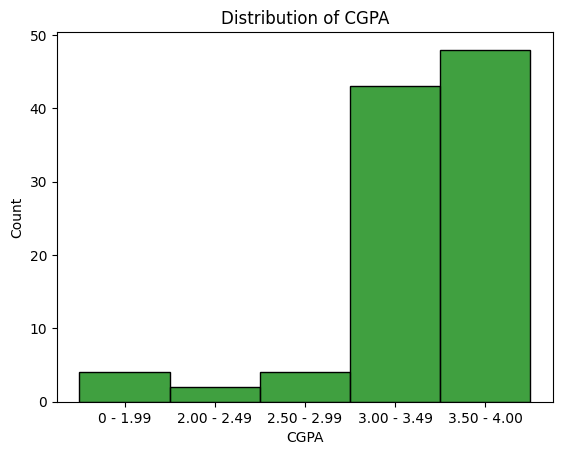

In [153]:
# plotting the bar chart for CGPA:
sns.histplot(data=df, x="CGPA", color="green")
plt.title("Distribution of CGPA")
# plt.xticks(rotation=45)  # Rotates the range text so they don't overlap
plt.show()

**Exercise 5: Comparing Anxiety Levels Across Different Genders**

**Objective**: Use a bar plot to compare the proportion of students experiencing anxiety across different genders.
**Dataset Overview:** The dataset includes columns: ‘Do you have Anxiety?’ and ‘Choose your gender’.

**Tasks**:
- Import necessary libraries.
- Use Seaborn to create a bar plot comparing anxiety levels across genders from the dataset df.
- Customize the plot with an appropriate color palette and add a title.
- Display the plot.

In [154]:
# rename columns:
df = df.rename(columns={'Do you have Anxiety?': 'anxiety','Choose your gender': 'gender'})

In [155]:
# tunringin anxiety into int numbers 1 (yes)/0 (no):
df['anxiety'] = df['anxiety'].apply(lambda x: 1 if x == 'Yes' else 0)

In [156]:
anxiety = df['anxiety'].groupby(df['gender']).value_counts()
print(anxiety)

gender  anxiety
Female  0          51
        1          24
Male    0          16
        1          10
Name: count, dtype: int64


In [157]:
# Checking values for barplot
df['anxiety'].groupby(df['gender']).value_counts(1) # .value_counts(normalize=True) same

gender  anxiety
Female  0          0.680000
        1          0.320000
Male    0          0.615385
        1          0.384615
Name: proportion, dtype: float64

gender
Female    0.320000
Male      0.384615
Name: anxiety, dtype: float64


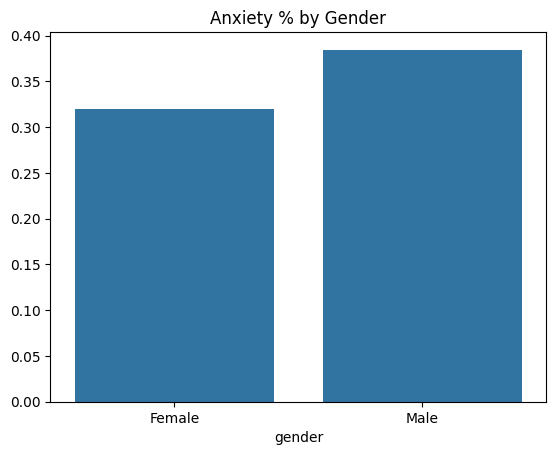

In [158]:
# barplot via manual values calcs to parse to the plot:
anxiety_freq = df['anxiety'].groupby(df['gender']).sum()/df['anxiety'].groupby(df['gender']).count()
print(anxiety_freq)

bar_x = anxiety_freq.index
bar_y = anxiety_freq.values

ax = sns.barplot(x=bar_x, y=bar_y)
#ax.bar_label(ax.containers[0],labels = [f"{v.get_height() * 100:.1f}%" for v in ax.containers[0]])
plt.title('Anxiety % by Gender')
plt.show()

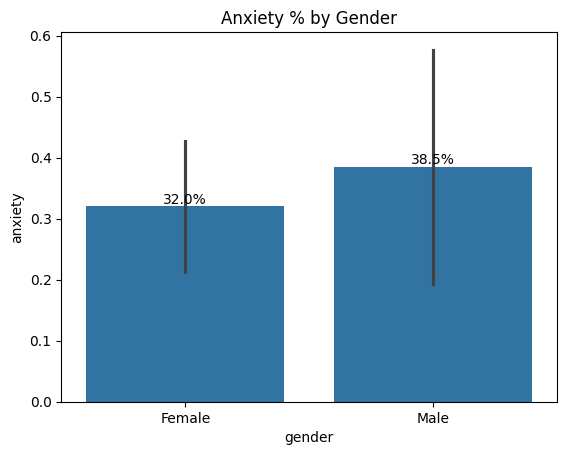

In [159]:
# plotting via bar chart where sns.barplot automatically plots relative frequencies per category since they have 0,1 values
ax = sns.barplot(x='gender', y='anxiety', data=df)
ax.bar_label(ax.containers[0],labels = [f"{v.get_height() * 100:.1f}%" for v in ax.containers[0]])
plt.title('Anxiety % by Gender')
plt.show()

**Exercise 6: Exploring the Relationship Between Age and Panic Attacks**

**Objective**: Create a scatter plot to explore the relationship between students’ age and the occurrence of panic attacks.

**Dataset Overview:** The dataset includes columns: ‘Age’ and ‘Do you have Panic Attacks?’.

**Tasks**:
- Import necessary libraries.
- Convert panic attack responses to numeric values (e.g., Yes=1, No=0).
- Use Seaborn’s scatterplot to create a scatter plot with ‘Age’ on the x-axis and numeric panic attack responses on the y-axis.
- Customize the plot to improve readability by adding labels, a title, and adjusting point styles.
- Display the plot.

In [162]:
# rename columns:
df = df.rename(columns={'Do you have Panic attack?': 'panic_attacks'})

In [165]:
df['panic_attacks'] = [1 if x == 'Yes' else 0 for x in df['panic_attacks']]
df.head(3)

,Timestamp,gender,Age,What is your course?,Your current year of Study,CGPA,Marital status,Do you have Depression?,anxiety,panic_attacks,Did you seek any specialist for a treatment?
0,8/7/2020 12:02,Female,18.0,Engineering,year 1,3.00 - 3.49,No,Yes,0,1,No
1,8/7/2020 12:04,Male,21.0,Islamic education,year 2,3.00 - 3.49,No,No,1,0,No
2,8/7/2020 12:05,Male,19.0,BIT,Year 1,3.00 - 3.49,No,Yes,1,1,No


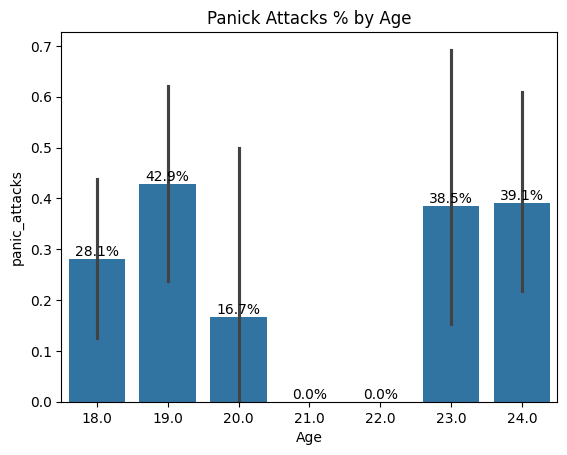

In [167]:
# scatter plot doesn't make sense as 1 variable panick_attacks only has two numeric values 0,1 and Age also only 7 uique value 18-24, so it will be just 14 dots.
# Better bar plot as before
ax = sns.barplot(x='Age', y='panic_attacks', data=df)
ax.bar_label(ax.containers[0],labels = [f"{v.get_height() * 100:.1f}%" for v in ax.containers[0]])
plt.title('Panick Attacks % by Age')
plt.show()

# sns.barplot(x='Age', y='panic_attacks', data=df, aspect=1.5, height=5)
# plt.title('Scatter Plot with Regression Line')
# plt.show()